In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from sbi import utils as utils
from sbi import analysis as analysis

/home/dingeldein/Venvs/fret_sbi/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import sys
from pathlib import Path
import yaml

project_root = Path.cwd().resolve().parent if Path.cwd().name == "analysis" else Path.cwd().resolve()
src_dir = project_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from simulator import smFRET_simulator_wrapper_from_config
from priors import generate_posterior_prior_from_config
from utils import eval_spline_from_config

In [3]:
outputs_root = project_root / "outputs"

run_selector = "latest"
# Example explicit selector:
# run_selector = "highnodes/2026-03-16/16-07-10"


def resolve_run_dir(selector: str) -> Path:
    if selector != "latest":
        candidate = (outputs_root / selector).resolve()
        if not candidate.exists():
            raise FileNotFoundError(f"Run directory not found: {candidate}")
        return candidate

    hydra_configs = list(outputs_root.rglob(".hydra/config.yaml"))
    if not hydra_configs:
        raise FileNotFoundError(f"No Hydra run found below {outputs_root}")
    return max(hydra_configs, key=lambda p: p.stat().st_mtime).parent.parent


def resolve_data_config(run_dir: Path) -> Path:
    copied = run_dir / "data_config.yaml"
    if copied.exists():
        return copied

    hydra_cfg_path = run_dir / ".hydra" / "config.yaml"
    if not hydra_cfg_path.exists():
        raise FileNotFoundError(
            f"Could not resolve data config: missing {copied} and {hydra_cfg_path}"
        )

    hydra_cfg = yaml.safe_load(hydra_cfg_path.read_text())
    data_dir = project_root / hydra_cfg["data"]["data_dir"]
    fallback = data_dir / "config.yaml"
    if not fallback.exists():
        raise FileNotFoundError(f"Data config not found: {fallback}")
    return fallback


run_dir = resolve_run_dir(run_selector)
data_cfg = resolve_data_config(run_dir)
print(f"run_dir  : {run_dir}")
print(f"data_cfg : {data_cfg}")

run_dir  : /home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/2026-03-17/09-40-23
data_cfg : /home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/2026-03-17/09-40-23/data_config.yaml


In [4]:
prior = generate_posterior_prior_from_config(str(data_cfg), device="cpu")
eval_spline = eval_spline_from_config(str(data_cfg))

In [5]:
samples = prior.sample((10000,))

/tmp/ipykernel_1107536/3847213529.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=13)


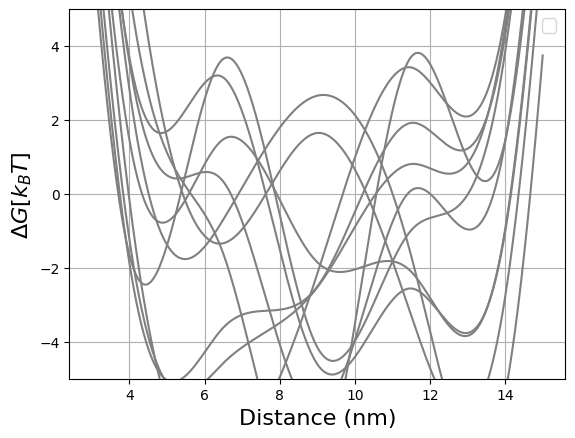

In [6]:
samples = prior.sample((10,))
for i in range(10):
    x, y = eval_spline(
        params=samples[i] - samples[i].mean(),  # Shift to zero mean for better visualization
        x_eval=np.linspace(3, 15, 1000),
    )
    plt.plot(x, y, color='gray', alpha=1)
plt.xlabel("Distance (nm)", fontsize=16)
plt.ylabel(r"$\Delta G [k_{B}T]$", fontsize=16)
plt.ylim(-5, 5)
plt.grid()
plt.legend(fontsize=13)